In [3]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
import sympy as sp

# Khai báo Hàm và Tính toán Gradient bằng SymPy

# hàm symbolic f(x, y)
x_sym, y_sym = sp.symbols('x y')
f_sym = (sp.sin(x_sym/4) + sp.cos(y_sym/4) - sp.sin(x_sym*y_sym/16) +
         sp.cos(x_sym**2/16) + sp.sin(y_sym**2/16))

# dùng sympy để tính đạo hàm riêng x y
fx_sym = sp.diff(f_sym, x_sym)
fy_sym = sp.diff(f_sym, y_sym)

# dùng lamda tối ưu tính toán f_sym
f_func = sp.lambdify((x_sym, y_sym), f_sym, 'numpy')
fx_func = sp.lambdify((x_sym, y_sym), fx_sym, 'numpy')
fy_func = sp.lambdify((x_sym, y_sym), fy_sym, 'numpy')


In [4]:
# Hill Climbing
class HillClimbing:
    """
    Hill Climbing Algorithm với 3 cải tiến chính:
    1. O(1) neighbor selection bằng Gradient Ascent
    2. Adaptive Step Size (giảm dần alpha)
    3. Random Restart khi mắc kẹt tại Local Maxima
    """

    def __init__(self, f_func, fx_func, fy_func, initial_point=(0.0, 0.0),
                 step_size=0.5, max_iter=500, epsilon=1e-6):
        self.f = f_func
        self.fx = fx_func # đạo hàm x
        self.fy = fy_func # đạo hàm y
        self.current_x, self.current_y = initial_point
        self.alpha = step_size
        self.initial_alpha = step_size # (0,0)
        self.max_iter = max_iter
        self.epsilon = epsilon # ngưỡng dừng
        self.path = [(self.current_x, self.current_y)]
        self.stuck_count = 0
        self.restart_count = 0

    def _determine_best_neighbor(self):
        """
        Phần 1: Xác định hướng đi tốt nhất bằng Gradient Ascent, dùng vector Gradient để chỉ hướng
        """
        grad_x = self.fx(self.current_x, self.current_y)
        grad_y = self.fy(self.current_x, self.current_y)
        return np.array([grad_x, grad_y])

    def _control_step_size(self, iteration):
        """
        Phần 2: Kiểm soát kích thước bước nhảy động.
        Sử dụng Exponential Decay để giảm dần alpha theo iteration
        """
        decay_rate = 0.95
        self.alpha = self.initial_alpha * (decay_rate ** iteration)
        self.alpha = max(self.alpha, 0.001)  # Giới hạn alpha tối thiểu

    def _handle_local_maxima(self):
        """
        Phần 3: Xử lý khi không có hàng xóm tốt hơn (Local Maxima).
        Thực hiện Random Restart với nhiễu ngẫu nhiên.
        """
        self.restart_count += 1
        print(f"  [Restart #{self.restart_count}] Phát hiện Local Maxima tại "
              f"({self.current_x:.3f}, {self.current_y:.3f}), "
              f"f = {self.f(self.current_x, self.current_y):.4f}")

        # Random restart trong vùng rộng hơn
        perturbation_scale = 2.0 + self.restart_count * 0.5
        self.current_x += np.random.randn() * perturbation_scale
        self.current_y += np.random.randn() * perturbation_scale

        # Reset alpha về giá trị cao
        self.alpha = self.initial_alpha * 0.7
        self.path.append((self.current_x, self.current_y))
        self.stuck_count = 0

        print(f"- Khởi động lại tại ({self.current_x:.3f}, {self.current_y:.3f})")

    def run(self):
        print(f"Start Hill Climbing from O({self.current_x}, {self.current_y})")

        for i in range(self.max_iter):
            # Xác định hướng di chuyển O(1) bằng Gradient
            gradient = self._determine_best_neighbor()
            grad_norm = np.linalg.norm(gradient)

            # Kiểm soát step size động
            self._control_step_size(i)

            # kiểm tra điều kiện dừng (Gradient quá nhỏ)
            if grad_norm < self.epsilon:
                self.stuck_count += 1

                # Stuck>=(10 iterations), use Random Restart
                if self.stuck_count >= 10:
                    # Giới hạn lần lặp tránh bug
                    if self.restart_count >= 5:
                        print(f"\n[Iteration {i}] Đã restart {self.restart_count} lần, dừng thuật toán")
                        break
                    self._handle_local_maxima()
                continue

            # Reset stuck count nếu tìm thấy gradient tốt
            self.stuck_count = 0

            # (Gradient Ascent)
            direction = gradient / grad_norm  # Chuẩn hóa
            next_x = self.current_x + self.alpha * direction[0]
            next_y = self.current_y + self.alpha * direction[1]

            # Kiểm tra cải thiện
            current_value = self.f(self.current_x, self.current_y)
            next_value = self.f(next_x, next_y)

            if next_value > current_value:
                # Cập nhật trạng thái
                self.current_x, self.current_y = next_x, next_y
                self.path.append((self.current_x, self.current_y))

                # In tiến trình mỗi 50 iterations
                if (i + 1) % 50 == 0:
                    print(f"[Iter {i+1:3d}] f({self.current_x:.3f}, {self.current_y:.3f}) = {next_value:.4f}")

        # Kết quả
        final_value = self.f(self.current_x, self.current_y)
        print(f"Vị trí tối ưu: x = {self.current_x:.6f}, y = {self.current_y:.6f}")
        print(f"Giá trị f lớn nhất: {final_value:.6f}")
        print(f"Số điểm đã khám phá: {len(self.path)}")
        print(f"Số lần Random Restart: {self.restart_count}")
        return self.path


In [6]:
#Khởi tạo và chạy thuật toán
hc_agent = HillClimbing(
    f_func, fx_func, fy_func,
    initial_point=(0.0, 0.0),
    step_size=0.5,
    max_iter=500,
    epsilon=1e-6
)
search_path = hc_agent.run()


Start Hill Climbing from O(0.0, 0.0)
[Iter  50] f(3.536, -4.698) = 3.7124
[Iter 100] f(3.527, -4.682) = 3.7125
Vị trí tối ưu: x = 3.526290, y = -4.680395
Giá trị f lớn nhất: 3.712520
Số điểm đã khám phá: 76
Số lần Random Restart: 0


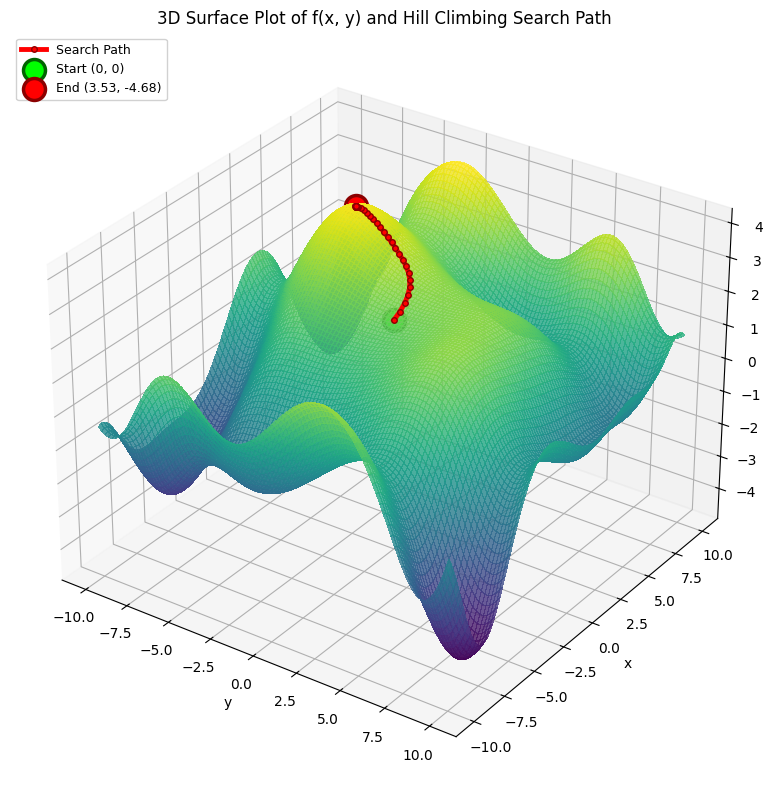

In [9]:
# Vẽ đồ thị
X = np.linspace(-10, 10, 500)
Y = np.linspace(-10, 10, 500)
X_grid, Y_grid = np.meshgrid(X, Y)
Z_grid = f_func(X_grid, Y_grid)
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')

# cmap='viridis' tạo màu sắc như yêu cầu của thầy
surf = ax.plot_surface(Y_grid, X_grid, Z_grid,
                       cmap='viridis',
                       alpha=0.8,
                       rstride=5,
                       cstride=5,
                       linewidth=0,
                       antialiased=False)

# RED PATH
path_x = [p[0] for p in search_path]
path_y = [p[1] for p in search_path]
path_z = [f_func(x, y) for x, y in search_path]

#  draw a red path to illustrate visited points along the search path
ax.plot(path_y, path_x, path_z,
        color='#FF0000',  # Màu đỏ thuần
        marker='o',
        markersize=4,
        linestyle='-',
        linewidth=3.5,  # Tăng độ dày
        label='Search Path',
        markeredgecolor='darkred',  # Viền đỏ đậm cho marker
        markeredgewidth=1,
        zorder=100)

# Start-green End-red
ax.scatter([path_y[0]], [path_x[0]], [path_z[0]],
          color='lime', s=250, marker='o',
          edgecolors='darkgreen', linewidth=2.5,
          label='Start (0, 0)', zorder=101)

ax.scatter([path_y[-1]], [path_x[-1]], [path_z[-1]],
          color='red', s=250, marker='o',
          edgecolors='darkred', linewidth=2.5,
          label=f'End ({path_x[-1]:.2f}, {path_y[-1]:.2f})', zorder=101)

ax.set_xlabel('y')
ax.set_ylabel('x')
ax.set_zlabel('f(y, x)')
ax.set_title('3D Surface Plot of f(x, y) and Hill Climbing Search Path')

ax.view_init(elev=30, azim=-55)

ax.legend(loc='upper left', fontsize=9, framealpha=0.9)

plt.tight_layout()
plt.show()